# Group 13 — Final Submission Notebook
**6001CMD Machine Learning · Telco Customer Churn (binary classification)**

Members: Boon (Parts A, B, Logistic Regression) · Chang (Part C, Random Forest) · Justin (Gradient Boosting, Parts F, G)

- Dataset: https://www.kaggle.com/blastchar/telco-customer-churn
- Repository: https://github.com/Winny04/Group13_6001CMD

**How to run:** select the project `venv` kernel (pinned `requirements.txt`) and use *Restart & Run All*.

**Reproducibility note.** All models follow the shared contract in `modules/shared/utils.py`: one 80/20 stratified split (`get_data()`), scaling and SMOTE inside the pipeline (`build_pipeline()`), 5-fold stratified CV, `RANDOM_STATE = 42`, `refit="f1"`, and the test set used only for final reporting. Tree-based models (RF, GB) give marginally different results on different computers even with fixed seeds, so the final tuned results were produced once on a single machine and saved in `results/*.json`. By default this notebook **loads** those saved results so every number matches the report. Set `RETRAIN = True` to re-run every grid search from scratch (≈5–10 minutes; tree-model numbers may then differ slightly).

In [1]:
import sys, json, time, pathlib, importlib, subprocess, warnings
warnings.filterwarnings("ignore")

# Locate the repository root (works whether the notebook runs from notebooks/ or the root)
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, imblearn
from IPython.display import Image, display
from sklearn.model_selection import GridSearchCV

from modules.shared.utils import get_data, build_pipeline, save_results, CV, SCORING, RANDOM_STATE, CONTINUOUS_COLS
dp = importlib.import_module("modules.02_preprocessing_pipeline.data_pipeline")

RETRAIN = False          # True = re-run all grid searches and overwrite results/*.json
RESULTS = ROOT / "results"
TREE_OUT = ROOT / "modules" / "03_tree_models_and_ensemble" / "outputs"
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

def load(name):
    return json.loads((RESULTS / f"{name}.json").read_text())

print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | imbalanced-learn {imblearn.__version__}")
print("Repository root:", ROOT)
print("RETRAIN =", RETRAIN)

Python 3.14.7 | scikit-learn 1.7.2 | imbalanced-learn 0.14.0
Repository root: C:\Development\Projects\Group6001CMD
RETRAIN = False


## Part A — Problem Definition
Predict whether a telecom customer will churn (`Churn` = Yes/No) so that retention offers can be targeted before the customer leaves. This is **supervised binary classification** on labelled historical data. Missing a churner (false negative) costs more than contacting a loyal customer, so **Recall** and **F1** are the primary metrics, with ROC-AUC for threshold-independent discrimination.

Success criteria agreed in the plan (on the held-out test set): **Recall ≥ 0.75, F1 ≥ 0.62, ROC-AUC ≥ 0.84**.

In [2]:
CRITERIA = {"recall": 0.75, "f1": 0.62, "roc_auc": 0.84}
CRITERIA

{'recall': 0.75, 'f1': 0.62, 'roc_auc': 0.84}

## Part B — Exploratory Data Analysis
### B.1 Raw data, types and data quality

In [3]:
raw = dp.load_raw()
print("Raw shape:", raw.shape)            # expected (7043, 21)
display(raw.head())
print(raw.dtypes.value_counts())

Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


object     18
int64       2
float64     1
Name: count, dtype: int64


In [4]:
tc = pd.to_numeric(raw["TotalCharges"], errors="coerce")
blank = tc.isna()
print("Blank TotalCharges values:", int(blank.sum()))
print("Tenure of those customers:", raw.loc[blank, "tenure"].unique())
print("Churn label of those customers:", raw.loc[blank, "Churn"].value_counts().to_dict())
print("Standard NaN values in other columns:", int(raw.drop(columns="TotalCharges").isna().sum().sum()))
print("Duplicate rows after dropping customerID:", int(raw.drop(columns="customerID").duplicated().sum()))

Blank TotalCharges values: 11
Tenure of those customers: [0]
Churn label of those customers: {'No': 11}
Standard NaN values in other columns: 0
Duplicate rows after dropping customerID: 22


### B.2 Descriptive statistics (continuous features)

In [5]:
num = pd.DataFrame({"tenure": raw["tenure"], "MonthlyCharges": raw["MonthlyCharges"], "TotalCharges": tc})
desc = num.describe().T
desc["skew"] = num.skew()
desc

,count,mean,std,min,25%,50%,75%,max,skew
tenure,7043.0,32.3711,24.5595,0.00,9.00,29.000,55.0000,72.00,0.2395
MonthlyCharges,7043.0,64.7617,30.0900,18.25,35.50,70.350,89.8500,118.75,-0.2205
TotalCharges,7032.0,2283.3004,2266.7714,18.80,401.45,1397.475,3794.7375,8684.80,0.9616


### B.3 Target class imbalance

{'No': 5174, 'Yes': 1869} | churn rate = 26.5% | imbalance ratio = 2.77 : 1


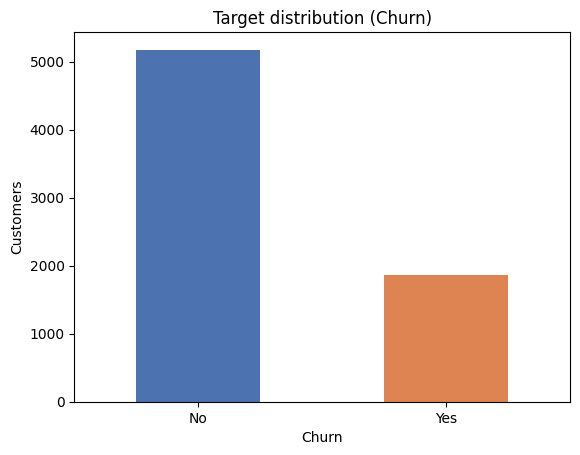

In [6]:
counts = raw["Churn"].value_counts()
print(counts.to_dict(), "| churn rate = %.1f%%" % (100 * counts["Yes"] / counts.sum()),
      "| imbalance ratio = %.2f : 1" % (counts["No"] / counts["Yes"]))
ax = counts.plot.bar(color=["#4C72B0", "#DD8452"], rot=0, title="Target distribution (Churn)")
ax.set_ylabel("Customers"); plt.show()

### B.4 Distributions and IQR outlier check

,all customers,non-churners,churners
feature,,,
tenure,0,0,23
MonthlyCharges,0,0,0
TotalCharges,0,0,109


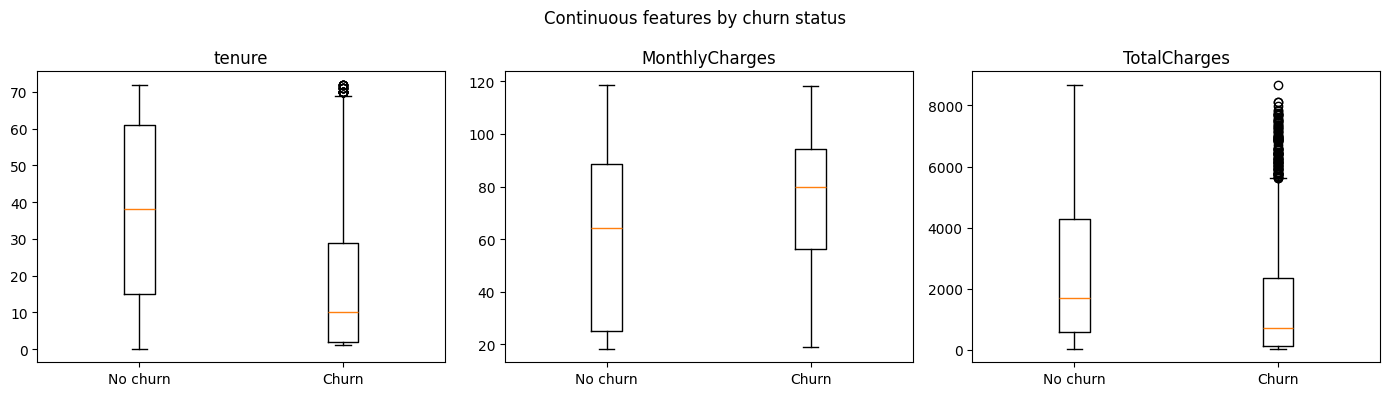

In [7]:
def iqr_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

rows = []
for col in num.columns:
    rows.append({"feature": col, "all customers": iqr_outliers(num[col]),
                 "non-churners": iqr_outliers(num.loc[raw["Churn"] == "No", col]),
                 "churners": iqr_outliers(num.loc[raw["Churn"] == "Yes", col])})
display(pd.DataFrame(rows).set_index("feature"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num.columns):
    data = [num.loc[raw["Churn"] == g, col].dropna() for g in ("No", "Yes")]
    ax.boxplot(data, tick_labels=["No churn", "Churn"]); ax.set_title(col)
plt.suptitle("Continuous features by churn status"); plt.tight_layout(); plt.show()

### B.5 Correlation and categorical churn drivers

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.199
Churn,-0.352,0.193,-0.199,1.000


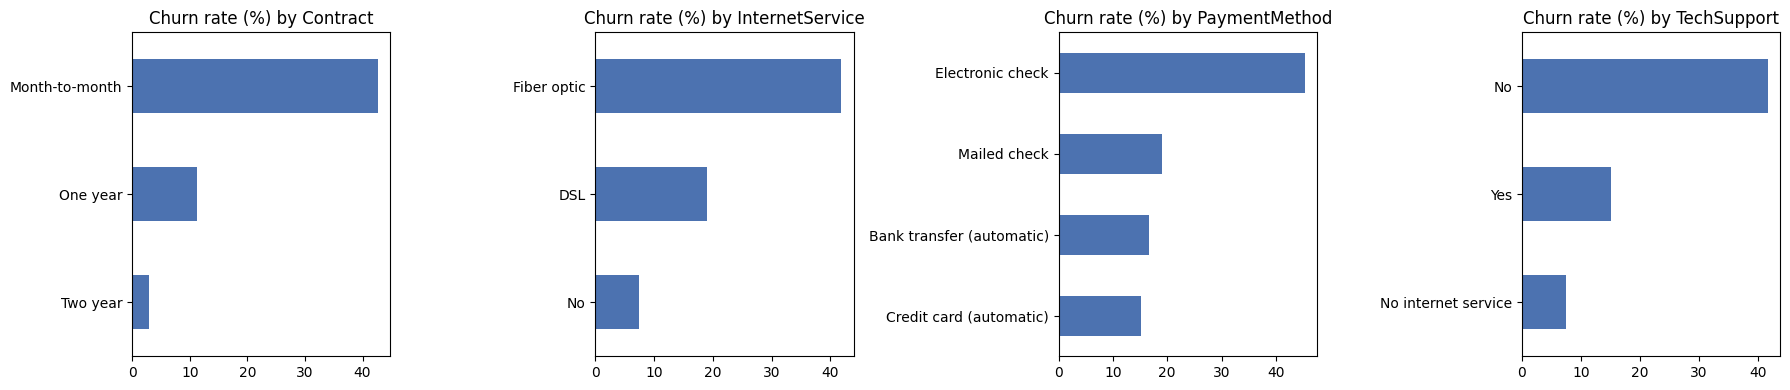

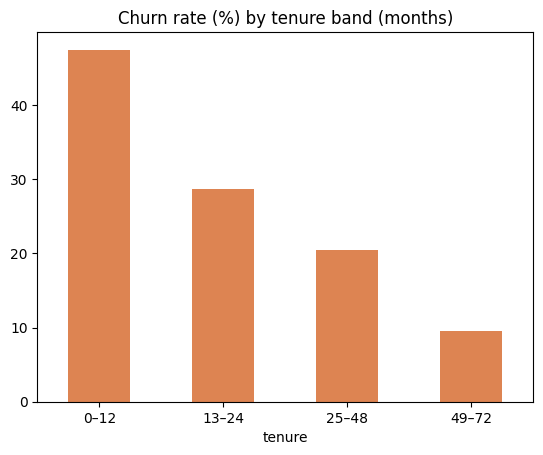

In [8]:
corr = num.assign(Churn=(raw["Churn"] == "Yes").astype(int)).corr()
display(corr.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod", "TechSupport"]):
    (raw.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values().plot.barh(ax=ax, color="#4C72B0"))
    ax.set_title(f"Churn rate (%) by {col}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

bands = pd.cut(raw["tenure"], [-1, 12, 24, 48, 72], labels=["0–12", "13–24", "25–48", "49–72"])
(raw.groupby(bands, observed=True)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    .plot.bar(rot=0, color="#DD8452", title="Churn rate (%) by tenure band (months)"))
plt.show()

## Part C — Data Preparation
### C.1 Cleaning, feature engineering and encoding (`data_pipeline.py`)
Blank `TotalCharges` → 0 (all 11 are tenure-0 customers), drop `customerID`, drop 22 duplicates, engineer `AvgMonthlyCharge` and `TotalServices`, recode redundant "No internet/phone service" levels, binary-map Yes/No columns, and one-hot encode with `drop_first=True`.

In [9]:
clean = dp.clean_and_encode(raw)
print("Cleaned shape:", clean.shape)
print("Any NaN:", bool(clean.isna().any().any()), "| all numeric:", all(np.issubdtype(t, np.number) for t in clean.dtypes))
display(clean.head())

# The submitted processed dataset must be exactly this output
processed = pd.read_csv(dp.PROCESSED_PATH)
print("data/processed/telco_churn_processed.csv matches pipeline output:",
      processed.shape == clean.shape and np.allclose(processed.values, clean.values))

Cleaned shape: (7021, 26)
Any NaN: False | all numeric: True


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,AvgMonthlyCharge,TotalServices,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn
0,0,0,1,0,1,0,0,0,1,0,...,29.8500,2,0,0,0,0,0,1,0,0
1,1,0,0,0,34,1,0,1,0,1,...,55.5735,4,0,0,1,0,0,0,1,0
2,1,0,0,0,2,1,0,1,1,0,...,54.0750,4,0,0,0,0,0,0,1,1
3,1,0,0,0,45,0,0,1,0,1,...,40.9056,4,0,0,1,0,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,75.8250,2,1,0,0,0,0,1,0,1


data/processed/telco_churn_processed.csv matches pipeline output: True


### C.2 Shared split and leakage-safe pipeline (`utils.py`)

In [10]:
X_train, X_test, y_train, y_test = get_data()
print(f"X_train {X_train.shape} | X_test {X_test.shape}")
print(f"Churn rate train {y_train.mean():.4f} | test {y_test.mean():.4f}")
print("Scaled (continuous) columns:", CONTINUOUS_COLS)

X_train (5616, 25) | X_test (1405, 25)
Churn rate train 0.2644 | test 0.2648
Scaled (continuous) columns: ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharge', 'TotalServices']


In [11]:
from sklearn.linear_model import LogisticRegression
pipe = build_pipeline(LogisticRegression())
print(pipe)   # StandardScaler (continuous cols) -> SMOTE (fit only) -> model

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges',
                                                   'AvgMonthlyCharge',
                                                   'TotalServices'])],
                                   verbose_feature_names_out=False)),
                ('smote', SMOTE(random_state=42)),
                ('model', LogisticRegression())])


### C.3 Automated pipeline validation (`test_pipeline.py`)

In [12]:
tp = importlib.import_module("modules.02_preprocessing_pipeline.test_pipeline")
tests = [n for n in dir(tp) if n.startswith("test_")]
passed = 0
for n in tests:
    try:
        getattr(tp, n)(); passed += 1; print("PASS", n)
    except AssertionError as e:
        print("FAIL", n, e)
print(f"{passed} of {len(tests)} pipeline checks passed")

PASS test_churn_ratio_preserved
PASS test_duplicates_removed
PASS test_engineered_features
PASS test_no_nans_no_id_all_numeric
PASS test_pipeline_never_resamples_at_predict
PASS test_raw_shape
PASS test_split_shapes
7 of 7 pipeline checks passed


### C.4 Correlation check and SMOTE impact (saved experiment results)
Produced by `correlation_check.py` and `smote_impact_experiment.py`.

In [13]:
cc = load("correlation_check")
display(pd.DataFrame(cc["key_pairs"]).T.round(4))
display(pd.Series(cc["corr_with_churn"], name="r with Churn").round(4).to_frame())
display(pd.DataFrame(cc["ablation_avg_monthly_charge"]).T[["f1", "roc_auc", "recall"]].round(4))

si = load("smote_impact")["results"]
rows = []
for model, treatments in si.items():
    for t, r in treatments.items():
        rows.append({"model": model, "treatment": t, **{k: r["cv"][k] for k in ("recall", "precision", "f1", "roc_auc")}})
pd.DataFrame(rows).set_index(["model", "treatment"]).round(3)

,pearson,spearman
AvgMonthlyCharge vs MonthlyCharges,0.9961,0.9915
TotalCharges vs tenure,0.8293,0.8911
TotalServices vs MonthlyCharges,0.8513,0.8508


,r with Churn
tenure,-0.3445
MonthlyCharges,0.2042
TotalCharges,-0.1889
AvgMonthlyCharge,0.2032
TotalServices,-0.0085


,f1,roc_auc,recall
logistic_regression | with AvgMonthlyCharge,0.6297,0.8452,0.7953
random_forest_tuned | with AvgMonthlyCharge,0.6379,0.8458,0.7394
logistic_regression | without AvgMonthlyCharge,0.6304,0.8454,0.7973
random_forest_tuned | without AvgMonthlyCharge,0.6316,0.8460,0.7367


recall  precision     f1  roc_auc
model               treatment                                   
logistic_regression none        0.544      0.653  0.594    0.846
                    smote       0.795      0.521  0.630    0.845
                    balanced    0.807      0.518  0.630    0.846
                    smotenc     0.783      0.522  0.627    0.841
random_forest       none        0.481      0.641  0.549    0.824
                    smote       0.605      0.604  0.605    0.828
                    balanced    0.472      0.650  0.547    0.827
                    smotenc     0.628      0.581  0.604    0.826

## Parts D & E — Base Models and Hyperparameter Tuning
Each model is tuned with `GridSearchCV` on the training set only, using the shared `CV` and `SCORING` and `refit="f1"`. The search objects below are the exact ones used by the training scripts; their grids are checked against the saved results.

In [14]:
def summary(res):
    rows = {}
    for stage in ("baseline", "tuned"):
        r = res[stage]
        rows[f"{stage} CV"] = r["cv"]
        rows[f"{stage} test"] = {k: v for k, v in r["test"].items() if k != "confusion_matrix"}
    df = pd.DataFrame(rows)[["baseline CV", "tuned CV", "baseline test", "tuned test"]]
    df.loc["train_f1"] = [res["baseline"]["train_f1"], res["tuned"]["train_f1"], np.nan, np.nan]
    return df.round(4)

def check_grid(search, res):
    same = {k: list(v) for k, v in search.param_grid.items()} == {k: list(v) for k, v in res["param_grid"].items()}
    print("Grid in this notebook matches the saved results:", same)
    print("Best params:", res["tuned"]["best_params"])

### Base Model 1 — Logistic Regression (Boon)

In [15]:
lr_grid = {"model__C": [0.01, 0.1, 1.0, 10.0],
           "model__penalty": ["l1", "l2"],
           "model__solver": ["liblinear"]}
lr_search = GridSearchCV(build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                         lr_grid, cv=CV, scoring=SCORING, refit="f1", n_jobs=-1, return_train_score=True)
if RETRAIN:
    lr_search.fit(X_train, y_train)
    save_results("logistic_regression", build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                 lr_search, X_train, y_train, X_test, y_test)
lr = load("logistic_regression")
check_grid(lr_search, lr)
summary(lr)

Grid in this notebook matches the saved results: True
Best params: {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}


,baseline CV,tuned CV,baseline test,tuned test
f1,0.6297,0.6333,0.6177,0.6137
roc_auc,0.8452,0.8452,0.8400,0.8400
recall,0.7953,0.7966,0.7688,0.7581
precision,0.5213,0.5256,0.5162,0.5155
accuracy,0.7528,0.7562,0.7480,0.7473
train_f1,0.6404,0.6376,NaN,NaN


Logistic Regression is deterministic, so the tuned model is refitted here to verify the saved test results and to show its coefficients (feature names are taken from the pipeline because the scaler moves the continuous columns first).

Refitted test F1 0.6137 vs saved 0.6137
Refitted test ROC-AUC 0.8400 vs saved 0.8400
Features zeroed by L1: ['PaymentMethod_Mailed check', 'gender', 'DeviceProtection', 'TotalServices']


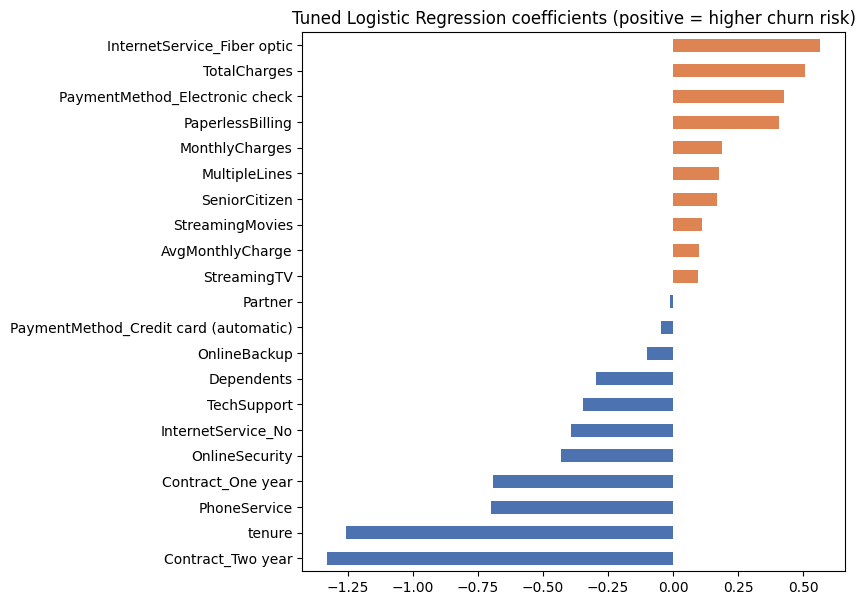

In [16]:
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
bp = {k.removeprefix("model__"): v for k, v in lr["tuned"]["best_params"].items()}
lr_model = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **bp)).fit(X_train, y_train)
proba = lr_model.predict_proba(X_test)[:, 1]
print(f"Refitted test F1 {f1_score(y_test, proba >= .5):.4f} vs saved {lr['tuned']['test']['f1']:.4f}")
print(f"Refitted test ROC-AUC {roc_auc_score(y_test, proba):.4f} vs saved {lr['tuned']['test']['roc_auc']:.4f}")

names = lr_model.named_steps["preprocess"].get_feature_names_out()
coef = pd.Series(lr_model.named_steps["model"].coef_[0], index=names).sort_values()
print("Features zeroed by L1:", list(coef[coef == 0].index))
coef[coef != 0].plot.barh(figsize=(7, 7), color=np.where(coef[coef != 0] > 0, "#DD8452", "#4C72B0"),
                          title="Tuned Logistic Regression coefficients (positive = higher churn risk)")
plt.show()

### Base Model 2 — Random Forest (Chang)

In [17]:
from sklearn.ensemble import RandomForestClassifier
rf_grid = {"model__n_estimators": [100, 200],
           "model__max_depth": [8, 12, None],
           "model__min_samples_split": [2, 5],
           "model__min_samples_leaf": [2, 4]}
make_rf = lambda: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_search = GridSearchCV(build_pipeline(make_rf()), rf_grid, cv=CV, scoring=SCORING,
                         refit="f1", n_jobs=-1, return_train_score=True)
if RETRAIN:
    rf_search.fit(X_train, y_train)
    save_results("random_forest", build_pipeline(make_rf()), rf_search, X_train, y_train, X_test, y_test)
rf = load("random_forest")
check_grid(rf_search, rf)
summary(rf)

Grid in this notebook matches the saved results: True
Best params: {'model__max_depth': 8, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 100}


,baseline CV,tuned CV,baseline test,tuned test
f1,0.5980,0.6371,0.5642,0.6272
roc_auc,0.8263,0.8459,0.8207,0.8397
recall,0.5973,0.7380,0.5376,0.7124
precision,0.5989,0.5606,0.5935,0.5603
accuracy,0.7877,0.7776,0.7801,0.7758
train_f1,0.9956,0.6968,NaN,NaN


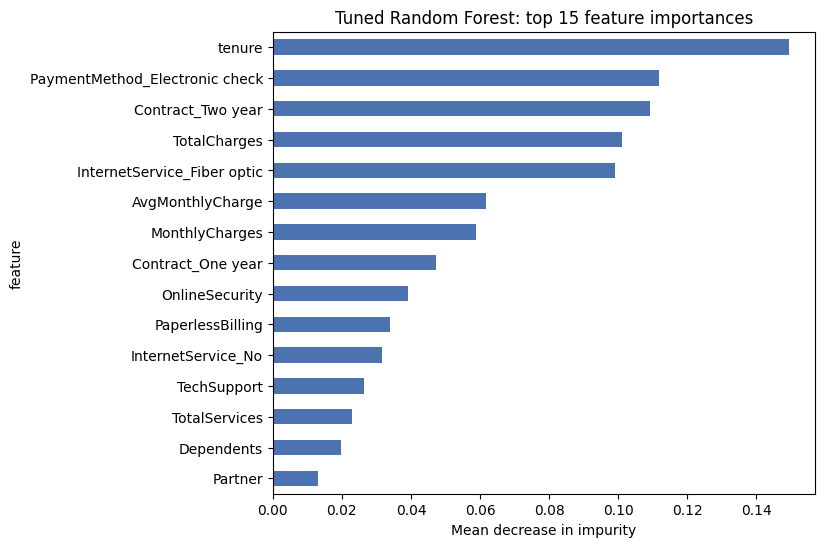

In [18]:
imp = pd.DataFrame(json.loads((RESULTS / "random_forest_importances.json").read_text())).set_index("feature")["importance"]
imp.head(15).sort_values().plot.barh(figsize=(7, 6), color="#4C72B0", title="Tuned Random Forest: top 15 feature importances")
plt.xlabel("Mean decrease in impurity"); plt.show()

### Base Model 3 — Gradient Boosting (Justin)

In [19]:
from sklearn.ensemble import GradientBoostingClassifier
gb_grid = {"model__n_estimators": [100, 150],
           "model__learning_rate": [0.05, 0.1],
           "model__max_depth": [3, 4],
           "model__subsample": [0.8, 1.0]}
gb_search = GridSearchCV(build_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)), gb_grid,
                         cv=CV, scoring=SCORING, refit="f1", n_jobs=-1, return_train_score=True)
if RETRAIN:
    gb_search.fit(X_train, y_train)
    save_results("gradient_boosting", build_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
                 gb_search, X_train, y_train, X_test, y_test)
gb = load("gradient_boosting")
check_grid(gb_search, gb)
summary(gb)

Grid in this notebook matches the saved results: True
Best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 0.8}


,baseline CV,tuned CV,baseline test,tuned test
f1,0.6285,0.6358,0.6253,0.6290
roc_auc,0.8458,0.8469,0.8408,0.8400
recall,0.6835,0.7320,0.6774,0.7177
precision,0.5820,0.5621,0.5806,0.5597
accuracy,0.7863,0.7783,0.7851,0.7758
train_f1,0.6609,0.6557,NaN,NaN


### Part D comparison — tuned base models (cross-validation)

In [20]:
NAMES = {"logistic_regression": "Logistic Regression", "random_forest": "Random Forest",
         "gradient_boosting": "Gradient Boosting", "ensemble": "Soft Voting Ensemble"}
base = {"logistic_regression": lr, "random_forest": rf, "gradient_boosting": gb}
pd.DataFrame({NAMES[k]: {**{f"CV {m}": v["tuned"]["cv"][m] for m in ("f1", "roc_auc", "recall", "precision")},
                         "CV F1 std": v["tuned"]["cv_std"]["f1"]} for k, v in base.items()}).T.round(4)

,CV f1,CV roc_auc,CV recall,CV precision,CV F1 std
Logistic Regression,0.6333,0.8452,0.7966,0.5256,0.0205
Random Forest,0.6371,0.8459,0.7380,0.5606,0.0207
Gradient Boosting,0.6358,0.8469,0.7320,0.5621,0.0236


## Part F — Ensemble Model (soft voting)
The two base models with the highest tuned **CV F1** (CV ROC-AUC as tie-breaker) are combined; the test set is not used for selection. Soft voting averages predicted churn probabilities, so the better-calibrated model's confidence is preserved.

In [21]:
ranked = sorted(base, key=lambda k: (-base[k]["tuned"]["cv"]["f1"], -base[k]["tuned"]["cv"]["roc_auc"]))
display(pd.DataFrame([{"rank": i + 1, "model": NAMES[k], "CV F1": base[k]["tuned"]["cv"]["f1"],
                       "CV ROC-AUC": base[k]["tuned"]["cv"]["roc_auc"]} for i, k in enumerate(ranked)]).set_index("rank").round(4))
chosen = ranked[:2]
print("Selected:", [NAMES[k] for k in chosen], "| excluded:", NAMES[ranked[2]])

,model,CV F1,CV ROC-AUC
rank,,,
1,Random Forest,0.6371,0.8459
2,Gradient Boosting,0.6358,0.8469
3,Logistic Regression,0.6333,0.8452


Selected: ['Random Forest', 'Gradient Boosting'] | excluded: Logistic Regression


In [22]:
from sklearn.ensemble import VotingClassifier
makers = {"logistic_regression": lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
          "random_forest": lambda: RandomForestClassifier(random_state=RANDOM_STATE),
          "gradient_boosting": lambda: GradientBoostingClassifier(random_state=RANDOM_STATE)}
members = [(k, makers[k]().set_params(**{p.removeprefix("model__"): v for p, v in base[k]["tuned"]["best_params"].items()}))
           for k in chosen]
ensemble_pipe = build_pipeline(VotingClassifier(estimators=members, voting="soft"))
print(ensemble_pipe)

ens = load("ensemble")
assert ens["selection"]["selected_models"] == chosen, "Saved ensemble used different members"
if RETRAIN:
    print("RETRAIN: run modules/03_tree_models_and_ensemble/run_ensemble.py to rebuild results/ensemble.json")
pd.DataFrame({"CV": ens["tuned"]["cv"],
              "test": {k: v for k, v in ens["tuned"]["test"].items() if k != "confusion_matrix"}}).round(4)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges',
                                                   'AvgMonthlyCharge',
                                                   'TotalServices'])],
                                   verbose_feature_names_out=False)),
                ('smote', SMOTE(random_state=42)),
                ('model',
                 VotingClassifier(estimators=[('random_forest',
                                               RandomForestClassifier(max_depth=8,
                                                                      min_samples_leaf=2,
                                                                      random_state=42)),
                                              ('gradient_boosting',
   

,CV,test
f1,0.6345,0.6295
roc_auc,0.8477,0.8411
recall,0.7327,0.7124
precision,0.5597,0.5638
accuracy,0.7767,0.7779


## Part G — Evaluation and Comparative Analysis
### G.1 Held-out test performance of all four tuned models

In [23]:
allres = {**base, "ensemble": ens}
test = pd.DataFrame({NAMES[k]: {m: v["tuned"]["test"][m] for m in ("accuracy", "precision", "recall", "f1", "roc_auc")}
                     for k, v in allres.items()}).T
display(test.round(4))

meets = pd.DataFrame({m: test[m] >= t for m, t in CRITERIA.items()})
meets["all three met"] = meets.all(axis=1)
meets

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.7473,0.5155,0.7581,0.6137,0.8400
Random Forest,0.7758,0.5603,0.7124,0.6272,0.8397
Gradient Boosting,0.7758,0.5597,0.7177,0.6290,0.8400
Soft Voting Ensemble,0.7779,0.5638,0.7124,0.6295,0.8411


,recall,f1,roc_auc,all three met
Logistic Regression,True,False,True,False
Random Forest,False,True,False,False
Gradient Boosting,False,True,False,False
Soft Voting Ensemble,False,True,True,False


### G.2 Confusion matrices

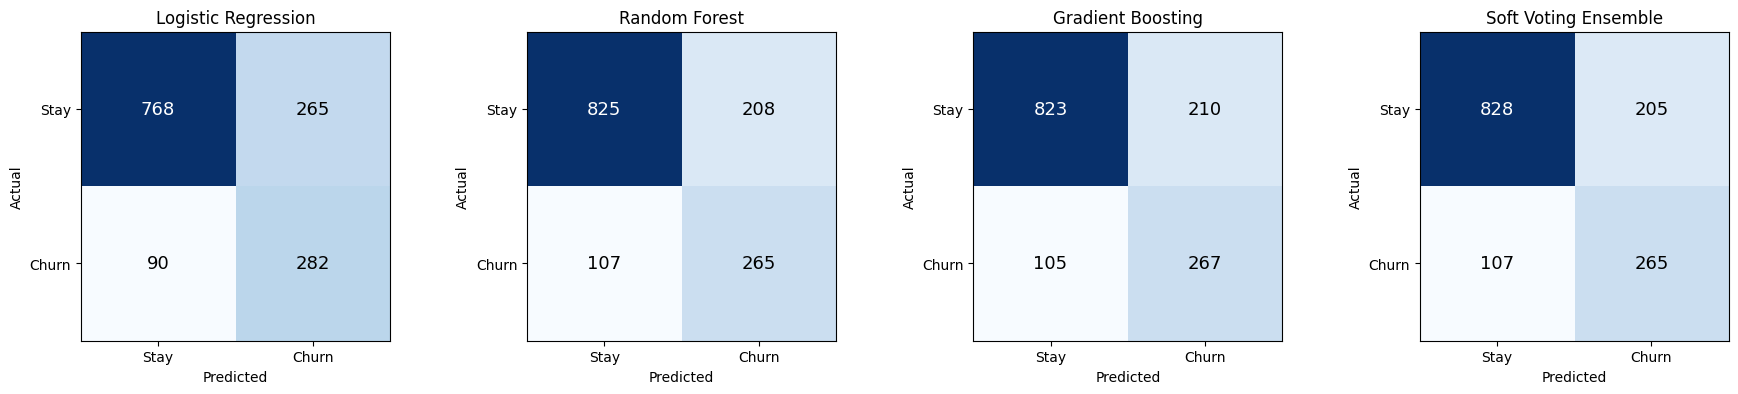

{'Logistic Regression': 'caught 282, missed 90', 'Random Forest': 'caught 265, missed 107', 'Gradient Boosting': 'caught 267, missed 105', 'Soft Voting Ensemble': 'caught 265, missed 107'}


In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (k, v) in zip(axes, allres.items()):
    cm = np.array(v["tuned"]["test"]["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    for (i, j), n in np.ndenumerate(cm):
        ax.text(j, i, n, ha="center", va="center", color="white" if n > cm.max() / 2 else "black", fontsize=13)
    ax.set_xticks([0, 1], ["Stay", "Churn"]); ax.set_yticks([0, 1], ["Stay", "Churn"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(NAMES[k])
plt.tight_layout(); plt.show()
print({NAMES[k]: f"caught {v['tuned']['test']['confusion_matrix'][1][1]}, missed {v['tuned']['test']['confusion_matrix'][1][0]}"
       for k, v in allres.items()})

### G.3 ROC curves
Generated by `run_evaluation.py` from the four fixed tuned models on the same machine that produced the saved results.

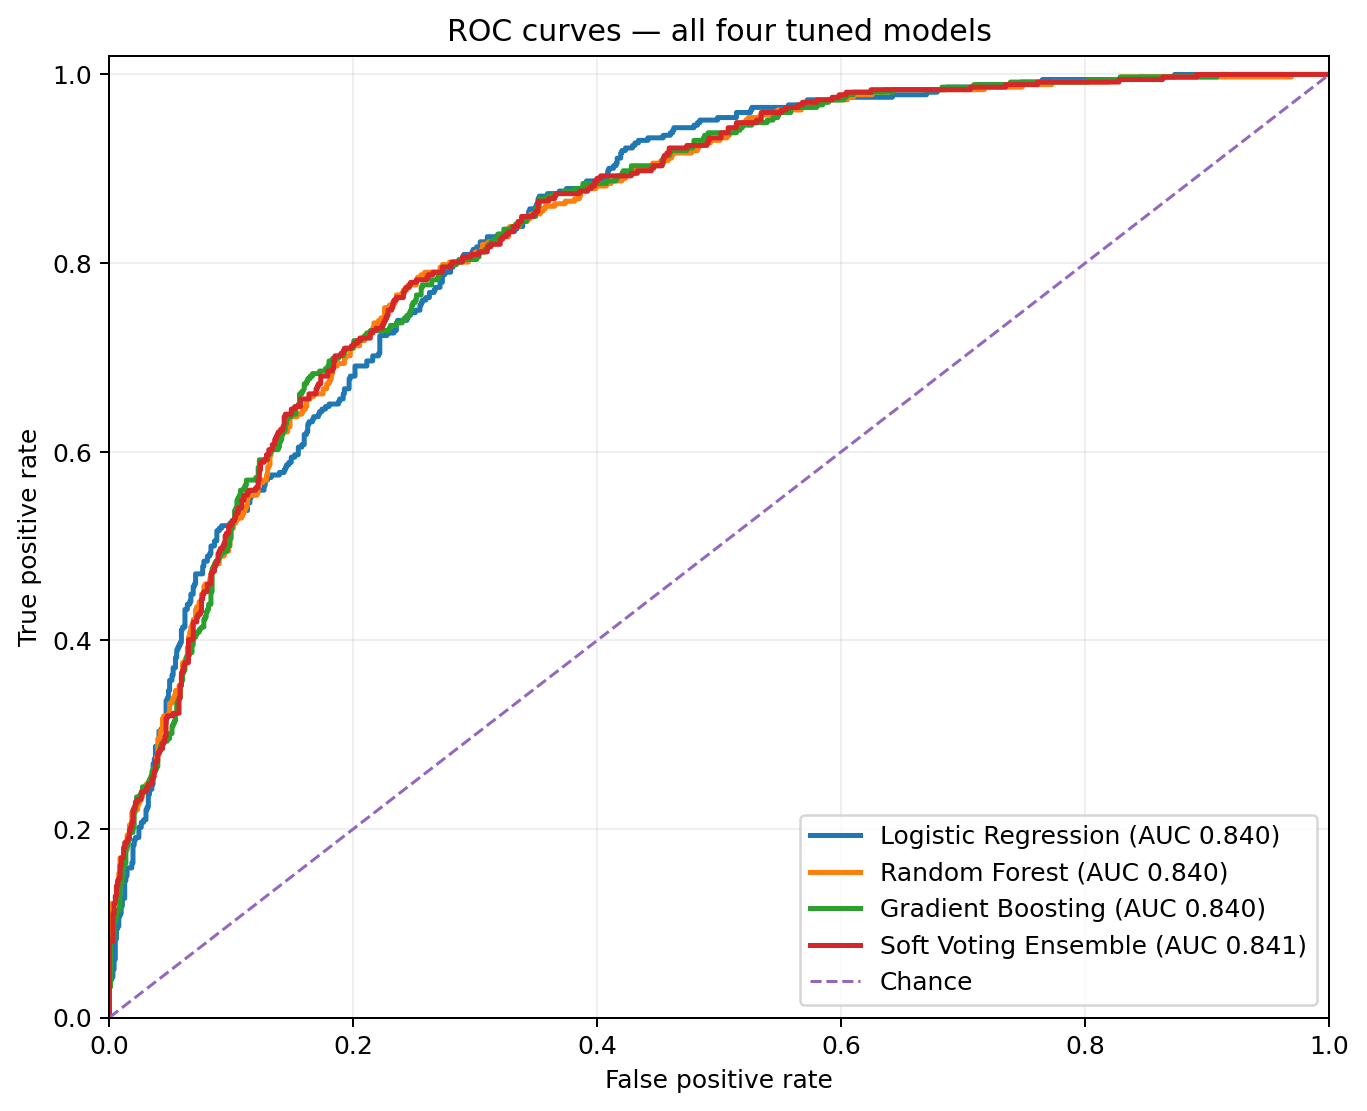

In [25]:
display(Image(filename=str(TREE_OUT / "roc_curves.png"), width=650))

### G.4 Overfitting and computational efficiency

In [26]:
eff = pd.DataFrame({NAMES[k]: {"train F1": v["tuned"]["train_f1"], "test F1": v["tuned"]["test"]["f1"],
                               "train − test gap": v["tuned"]["train_f1"] - v["tuned"]["test"]["f1"],
                               "fit time (s)": v["tuned"]["fit_time_s"],
                               "predict (ms / 1,000)": v["tuned"]["predict_ms_per_1000"]}
                    for k, v in allres.items()}).T
eff.round(4)

,train F1,test F1,train − test gap,fit time (s),"predict (ms / 1,000)"
Logistic Regression,0.6376,0.6137,0.0239,0.3479,2.3839
Random Forest,0.6968,0.6272,0.0696,0.2248,10.6034
Gradient Boosting,0.6557,0.6290,0.0267,1.6705,2.6765
Soft Voting Ensemble,0.6797,0.6295,0.0502,2.6200,14.2895


### G.5 Does the ensemble significantly improve on the best base model?
Paired comparison of the five CV fold F1 scores (same folds for both models).

In [27]:
best = ranked[0]
paired = pd.DataFrame({"ensemble F1": ens["tuned"]["cv_folds"]["f1"],
                       f"{NAMES[best]} F1": base[best]["tuned"]["cv_folds"]["f1"]}, index=range(1, 6))
paired["difference"] = paired.iloc[:, 0] - paired.iloc[:, 1]
display(paired.round(4))
print(f"Mean difference {paired['difference'].mean():.4f}; folds favouring the ensemble: {(paired['difference'] > 0).sum()} of 5")

,ensemble F1,Random Forest F1,difference
1,0.6484,0.6572,-0.0088
2,0.6241,0.6256,-0.0015
3,0.6252,0.6259,-0.0007
4,0.6647,0.6657,-0.0010
5,0.6101,0.6112,-0.0011


Mean difference -0.0026; folds favouring the ensemble: 0 of 5


### G.6 Deployment recommendation
No model meets all three criteria at the default 0.5 threshold. The ensemble has the highest test F1 and ROC-AUC, but its advantage over Gradient Boosting is negligible and it does not beat Random Forest in any CV fold. **Logistic Regression** is the only model that meets the Recall target and misses the fewest churners, and it is also the fastest and most interpretable, so it is the recommended deployment candidate for a recall-focused retention campaign, with decision-threshold tuning on validation data as the next step.

In [28]:
# Final check: confirm the notebook did not modify any saved result when RETRAIN is False
if not RETRAIN:
    print("Saved results were only read, not modified.")

Saved results were only read, not modified.
